In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [9]:
existencias=pd.read_excel('/Users/juanpablosolis/Desktop/Concentración TEC/Curso Python Alfredo/tratamiento inicial CLV/Datos_CLV_2026_Tec_v2.xlsx', sheet_name='Existencias_04_09_2026')
existencias.head()

,articulo_id,nombre_articulo,marca,nombre_almacen,existencias,valor_total_inventario
0,97759,10L MAX BUILD TRAY,Asiga,Almacén General,4,17308.44
1,295121,1L MAX LOW FORCE BUILD TRAY,Asiga,Almacén General,4,3749.14
2,309437,2-2 VALVULA DIRECCIONAL AGUA AIRE,Amann Girrbach,Almacén General,2,6458.84
3,85167,2L MAX BUILD PLASTIC TRAY FOR MAX 3D PRINTER,Asiga,Almacén General,1,1565.35
4,295124,2L ULTRA ULTRAGLOSS BUILD TRAY,Asiga,Almacén General,1,2905.36


In [16]:
num = existencias[['existencias', 'valor_total_inventario']]
num.describe()

matriz = num.corr()
print(matriz)

                        existencias  valor_total_inventario
existencias                1.000000                0.160989
valor_total_inventario     0.160989                1.000000


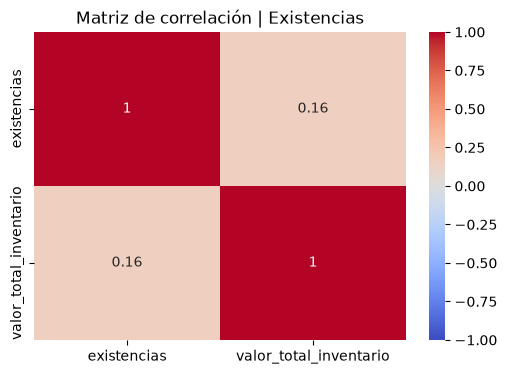

In [17]:
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación | Existencias")
plt.show()

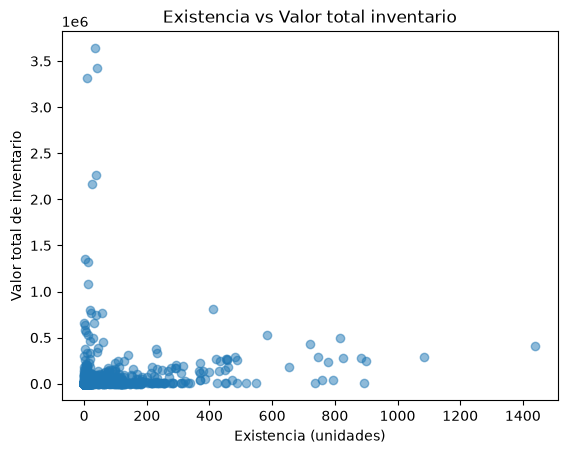

In [18]:
plt.scatter(num['existencias'], num['valor_total_inventario'], alpha=0.5)
plt.xlabel("Existencia (unidades)")
plt.ylabel("Valor total de inventario")
plt.title("Existencia vs Valor total inventario")
plt.show()

In [19]:
x = num[['existencias']]
y = num['valor_total_inventario']

modelo = LinearRegression()
modelo.fit(x, y)

m = modelo.coef_[0]
b = modelo.intercept_
r2 = modelo.score(x, y)

print(f"Ecuación: y = {m:.2f}x + {b:.2f}")
print(f"Pendiente (m): {m:.2f}")
print(f"Intercepto (b): {b:.2f}")
print(f"R^2: {r2:.4f}")

Ecuación: y = 279.84x + 14853.85
Pendiente (m): 279.84
Intercepto (b): 14853.85
R^2: 0.0259


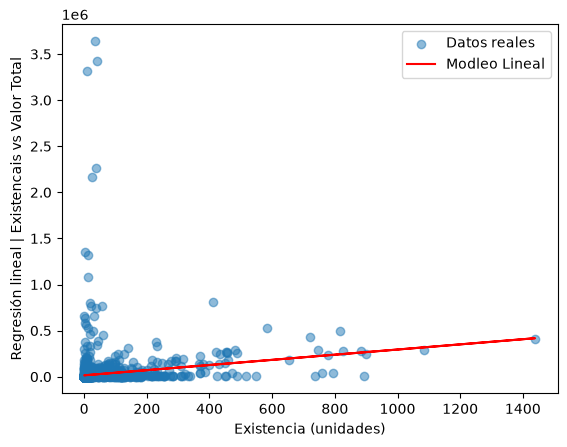

In [21]:
plt.scatter(x, y, alpha=0.5, label="Datos reales")
plt.plot(x, modelo.predict(x), color='red', label="Modleo Lineal")
plt.xlabel("Existencia (unidades)")
plt.ylabel("Regresión lineal | Existencais vs Valor Total")
plt.legend()
plt.show()

Justificaciones individuales
1. Rsultado del heatmap:
La correlación entre existencias y valor total es de 0.16. Positiva pero muy débil / irrelevante. 

2. ¿Por qué es positiva?
El valor total se calcula con existencias x costo unitario. Más unidades equivale a mayor valor total. 
Por eso la pendiente es positiva (m = 279.84)

3. ¿Por qué es tan débil?
El costo unitario varía mucho entre productos. Por eso pocas unidades de un artículo caro pueden valer mucho más que cientos de unidades baratas

4. Lógica de Negocio
LAs empresas suelen tener poco inventario de lo caro para tener liquidez y mucho de lo barato para tener buen flujo de $. Este comportamiento va en contra de la correlación y la debilita. Se ve en el scatter (valores altos (outliers) tienen existencias bajas)

5. Conclusión del modelo
Con R^2 = 0.026 las existencias por sí solas no sirven para predecir el valor total del inventario. Se necesitaría otra variable como precio unitario.